# Practical 7: Support Vector Machines with Linear and Non-linear Kernels

**Subject:** Machine Learning  |  **Type:** Supervised learning, classification

## Aim
Utilise **Support Vector Machine classifiers with linear and non-linear kernels** on a suitable open-access dataset and **compare classification performance** using appropriate evaluation metrics.

## Datasets
| Part | Dataset | Why |
|---|---|---|
| A | **Breast Cancer Wisconsin** (30 features, 2 classes) | Compare 4 kernels with full metrics |
| B | **Iris** (2 petal features) | Draw decision boundaries and support vectors |
| C | **make_moons** (synthetic, curved classes) | Shows clearly when a non-linear kernel is *needed* |
| D | Effect of **C** and **gamma**, and tuning with GridSearchCV | |

## Steps
1. Scale data and train SVMs with linear, polynomial, RBF and sigmoid kernels
2. Compare accuracy, precision, recall, F1 and confusion matrices
3. Visualise decision boundaries and support vectors
4. Show where the linear kernel fails (moons)
5. Effect of C and gamma
6. Tune hyperparameters with cross-validation

## Step 0: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer, load_iris, make_moons
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")

## Part A: Compare kernels on Breast Cancer (30 features)

In [2]:
data = load_breast_cancer()
X, y = data.data, 1 - data.target          # 1 = malignant (positive), 0 = benign
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)      # SVM needs scaling!
X_test_s = sc.transform(X_test)
print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)

Train: (426, 30) | Test: (143, 30)


In [3]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
rows, cms, models = [], {}, {}
for k in kernels:
    m = SVC(kernel=k, C=1.0, gamma="scale", random_state=42).fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    models[k] = m
    cms[k] = confusion_matrix(y_test, p)
    rows.append({"Kernel": k,
                 "Accuracy": accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p),
                 "Support vectors": int(m.n_support_.sum()),
                 "CV accuracy (5-fold)": cross_val_score(SVC(kernel=k, C=1.0, gamma="scale"), sc.transform(X), y, cv=5).mean()})
res = pd.DataFrame(rows).round(4)
res

,Kernel,Accuracy,Precision,Recall,F1,Support vectors,CV accuracy (5-fold)
0,linear,0.9580,1.0000,0.8868,0.9400,36,0.9719
1,poly,0.8951,1.0000,0.7170,0.8352,147,0.9016
2,rbf,0.9720,1.0000,0.9245,0.9608,103,0.9754
3,sigmoid,0.9510,0.9792,0.8868,0.9307,68,0.9526


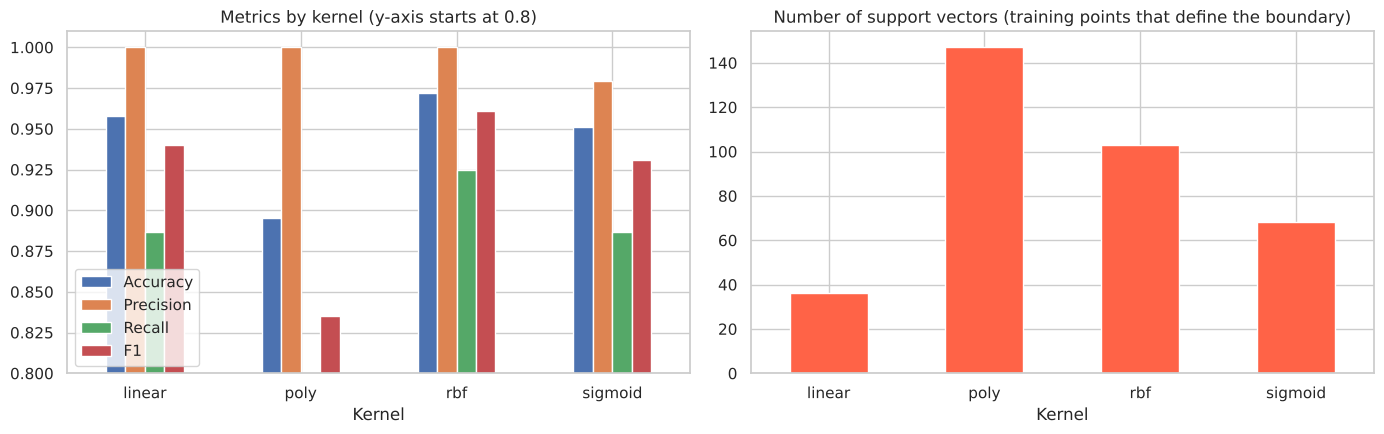

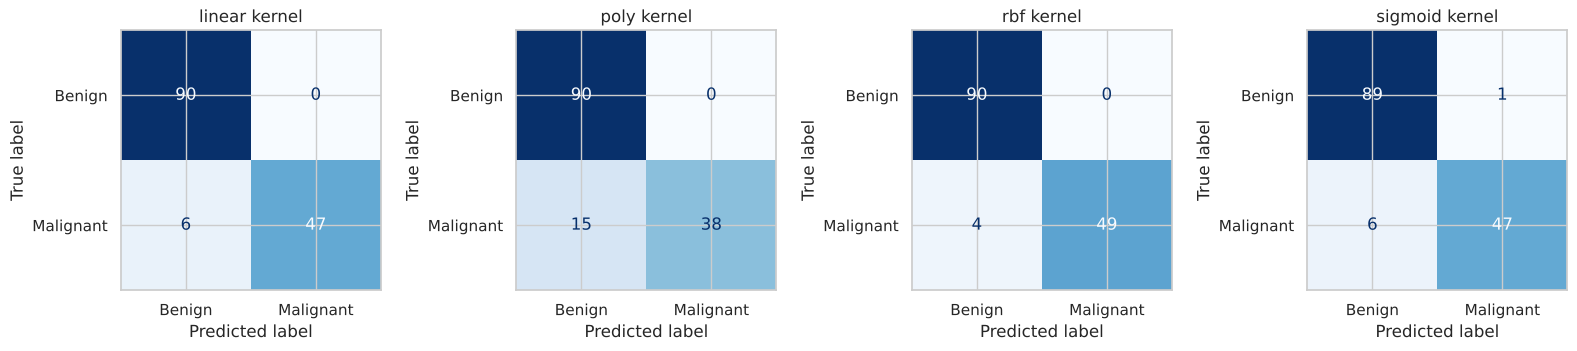

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
res.set_index("Kernel")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", ax=ax[0], rot=0)
ax[0].set_ylim(0.8, 1.01); ax[0].set_title("Metrics by kernel (y-axis starts at 0.8)"); ax[0].legend(loc="lower left")
res.set_index("Kernel")["Support vectors"].plot(kind="bar", ax=ax[1], color="tomato", rot=0)
ax[1].set_title("Number of support vectors (training points that define the boundary)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, k in zip(ax, kernels):
    ConfusionMatrixDisplay(cms[k], display_labels=["Benign", "Malignant"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"{k} kernel")
plt.tight_layout(); plt.show()

**How to read the graphs**
- **Metric bars:** compare kernels metric by metric. In my run **RBF was best (accuracy 0.972)**, **linear was close (0.958)**, sigmoid was 0.951 and **polynomial was clearly the weakest (0.895, recall only 0.72)**. Precision is about 1.0 for all kernels, so the differences are in **recall**: the weaker kernels miss more malignant cases.
- **Be careful with small differences:** the test set has only 143 samples, so one patient is about 0.7%. Linear vs RBF differ by only 2 patients, and cross-validation (last column of the table: 0.972 vs 0.975) shows they are essentially equal. Because the breast-cancer classes are almost linearly separable, a non-linear kernel is not needed here. The polynomial kernel with its default settings (degree 3) does poorly; it would need tuning of degree and `coef0`.
- **Support vector bars:** fewer support vectors means a simpler boundary that depends on fewer points. Linear has the fewest (36) and polynomial the most (147), which matches its poorer fit.
- **Confusion matrices:** the diagonal is correct predictions; FN (bottom-left) is a missed malignant case. The polynomial matrix shows the most FN.

## Part B: Decision boundaries on Iris (2 features)

Only two features can be drawn on a plot, so we use **petal length and petal width** (3 classes). Circled points are **support vectors**.

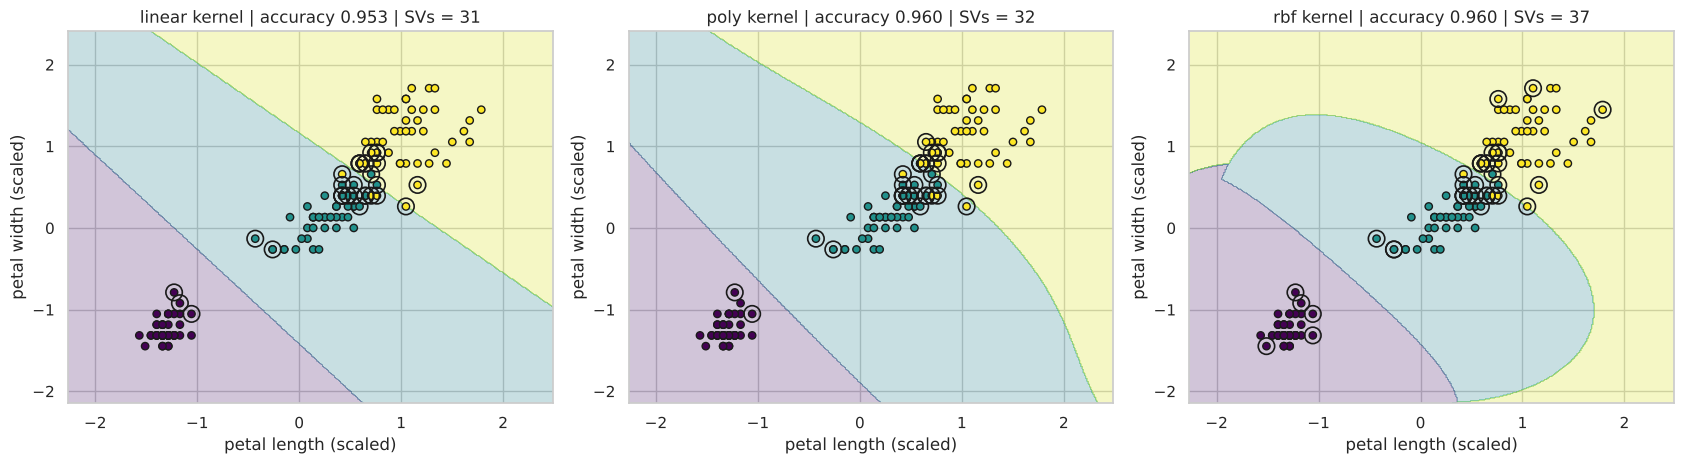

In [5]:
iris = load_iris()
Xi = StandardScaler().fit_transform(iris.data[:, 2:4])
yi = iris.target

def plot_boundary(ax, model, X, y, title, show_sv=True):
    x_min, x_max = X[:, 0].min() - 0.7, X[:, 0].max() + 0.7
    y_min, y_max = X[:, 1].min() - 0.7, X[:, 1].max() + 0.7
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm" if len(np.unique(y)) == 2 else "viridis")
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k", s=28, cmap="coolwarm" if len(np.unique(y)) == 2 else "viridis")
    if show_sv:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=140, facecolors="none", edgecolors="k", lw=1.2)
    ax.set_title(title)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a, (k, kw) in zip(ax, [("linear", {}), ("poly", {"degree": 3}), ("rbf", {})]):
    m = SVC(kernel=k, C=1, gamma="scale", **kw).fit(Xi, yi)
    plot_boundary(a, m, Xi, yi, f"{k} kernel | accuracy {m.score(Xi, yi):.3f} | SVs = {m.n_support_.sum()}")
    a.set_xlabel("petal length (scaled)"); a.set_ylabel("petal width (scaled)")
plt.tight_layout(); plt.show()

**How to read these:** the coloured regions are the areas where the model predicts each species, and the borders between colours are the **decision boundaries**. Dots are the data coloured by true species; a dot sitting in the wrong colour is misclassified. The **linear** kernel draws straight lines; **polynomial** and **RBF** draw curved boundaries. On Iris all give similar accuracy because the species are well separated. The circled points are the **support vectors**: the points nearest the boundary, which alone determine it.

## Part C: When the linear kernel fails (make_moons)

Two interleaving half-circles cannot be separated by a straight line.

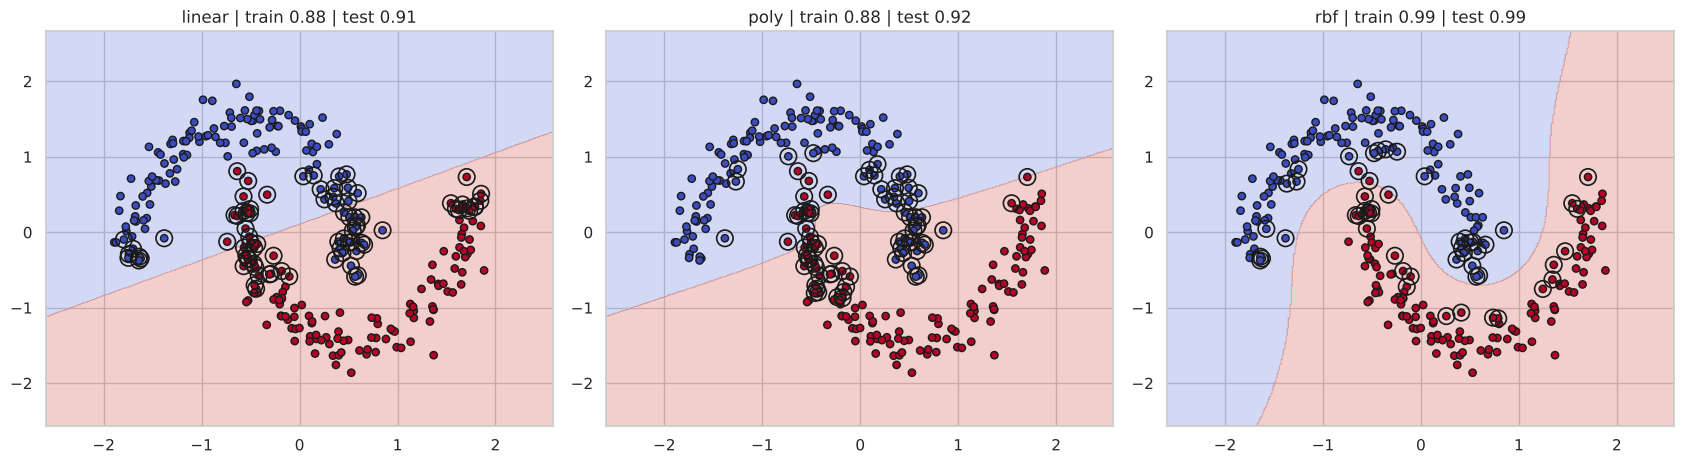

,Kernel,Train acc,Test acc
0,linear,0.879,0.908
1,poly,0.879,0.917
2,rbf,0.993,0.992


In [6]:
Xm, ym = make_moons(n_samples=400, noise=0.1, random_state=0)
Xm = StandardScaler().fit_transform(Xm)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=0, stratify=ym)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
rows = []
for a, (k, kw) in zip(ax, [("linear", {}), ("poly", {"degree": 3}), ("rbf", {})]):
    m = SVC(kernel=k, C=1, gamma="scale", **kw).fit(Xm_tr, ym_tr)
    tr, te = m.score(Xm_tr, ym_tr), m.score(Xm_te, ym_te)
    rows.append({"Kernel": k, "Train acc": round(tr, 3), "Test acc": round(te, 3)})
    plot_boundary(a, m, Xm_tr, ym_tr, f"{k} | train {tr:.2f} | test {te:.2f}")
plt.tight_layout(); plt.show()
pd.DataFrame(rows)

**How to read these:** the linear kernel can only draw a straight line, so it cuts across both moons and misclassifies about **9% of the test points (test accuracy about 0.91)**. The **RBF kernel bends the boundary around each moon** and reaches about **0.99**. (With more noise the gap shrinks, because noise blurs the shape the kernel is trying to follow; this data uses a small noise level of 0.1 so the effect is visible.) This is the whole point of the **kernel trick**: the data is implicitly mapped to a higher-dimensional space where a linear separator exists, and in the original space it appears curved.

## Part D: Effect of C and gamma (RBF kernel)

- **C** controls the trade-off between a wide margin and training errors. Small C: wide margin, more errors allowed (smoother). Large C: tries to classify every point correctly (wiggly, may overfit).
- **gamma** controls how far one point's influence reaches. Small gamma: far reach, smooth boundary. Large gamma: each point only affects its immediate surroundings, giving tight islands (overfit).

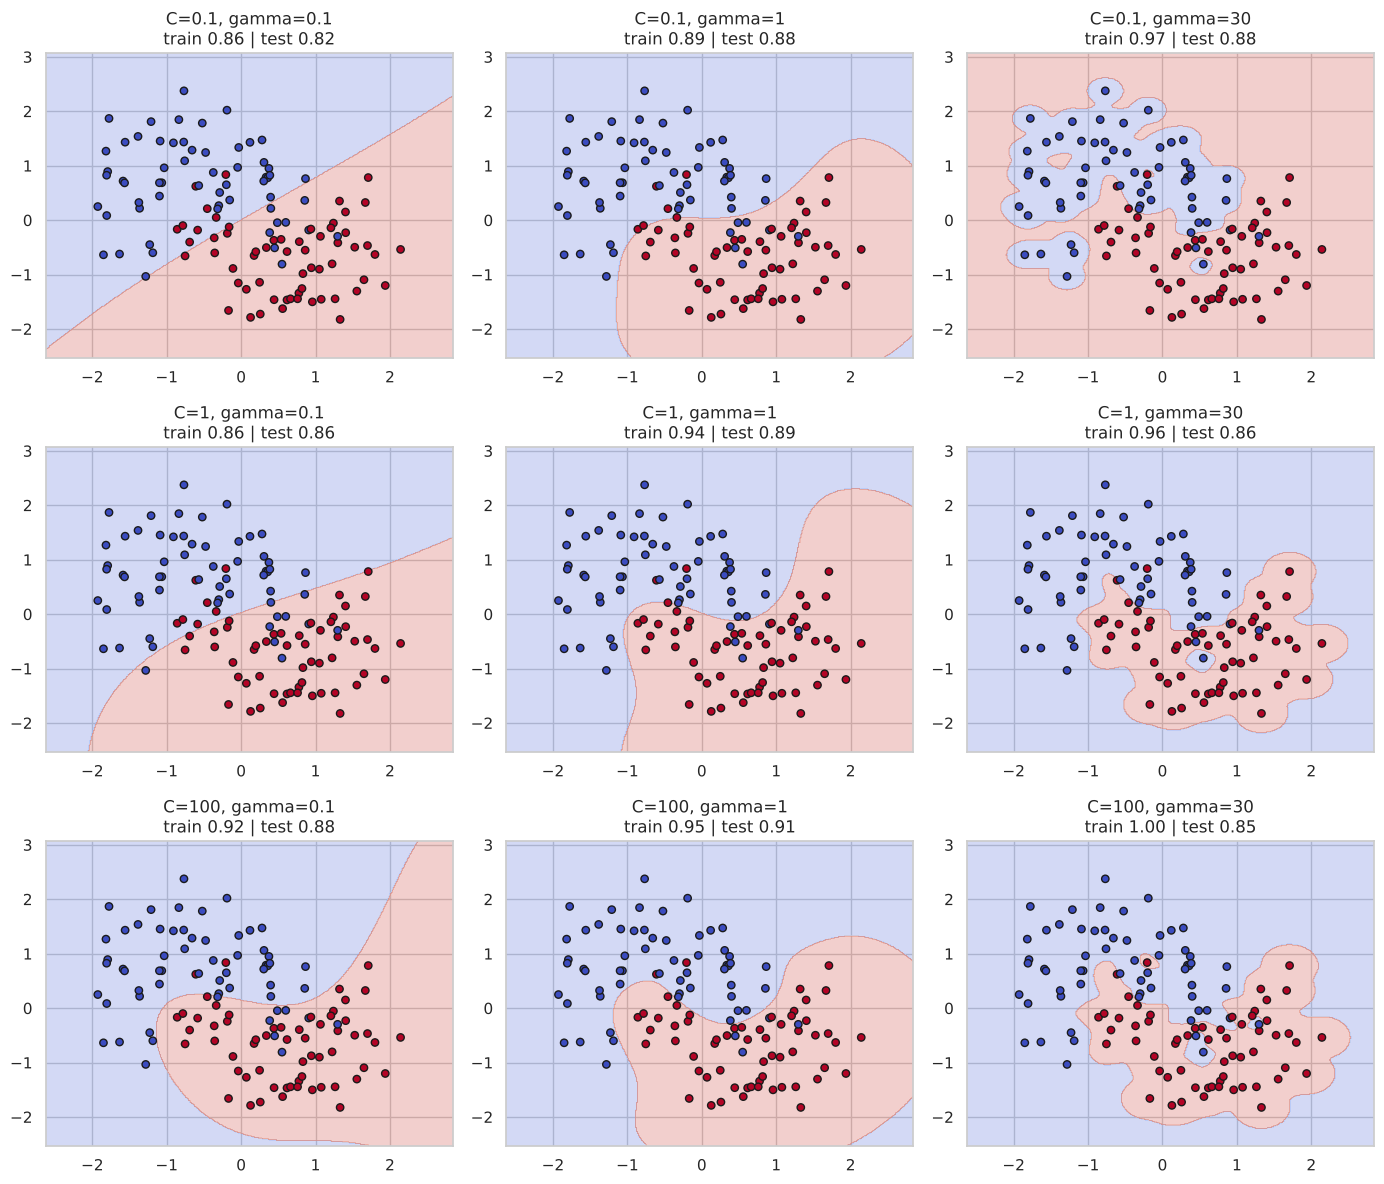

In [7]:
# A noisier, smaller dataset makes overfitting visible (with clean data large gamma looks fine)
Xn, yn = make_moons(n_samples=200, noise=0.3, random_state=1)
Xn = StandardScaler().fit_transform(Xn)
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xn, yn, test_size=0.4, random_state=1, stratify=yn)

Cs, gammas = [0.1, 1, 100], [0.1, 1, 30]
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for i, C in enumerate(Cs):
    for j, g in enumerate(gammas):
        m = SVC(kernel="rbf", C=C, gamma=g).fit(Xn_tr, yn_tr)
        plot_boundary(axes[i, j], m, Xn_tr, yn_tr, f"C={C}, gamma={g}\ntrain {m.score(Xn_tr, yn_tr):.2f} | test {m.score(Xn_te, yn_te):.2f}", show_sv=False)
plt.tight_layout(); plt.show()

**How to read this 3x3 grid** (noisy moons, 200 points): rows increase C downward, columns increase gamma to the right.
- **Top-left (small C, small gamma):** very smooth, almost straight boundary and low accuracy on both train and test (about 0.86 / 0.82): **underfitting** (high bias).
- **Bottom-right (C = 100, gamma = 30):** the boundary forms tight islands around individual points. Train accuracy is **1.00** but test accuracy drops (about 0.85): **overfitting** (high variance), because the model memorised the noise.
- **The middle region (gamma around 1)** gives a smooth curve that follows the moons with the best test accuracy (about 0.89 to 0.91): the best trade-off.
- Exact values depend on the random split; the pattern (train rises with C and gamma, test peaks in the middle) is what matters.

## Step 6: Tune C and gamma with GridSearchCV (Breast Cancer, RBF)

Best parameters: {'C': 10, 'gamma': 0.01}
Best CV accuracy: 0.9789
Test accuracy of tuned model: 0.9790


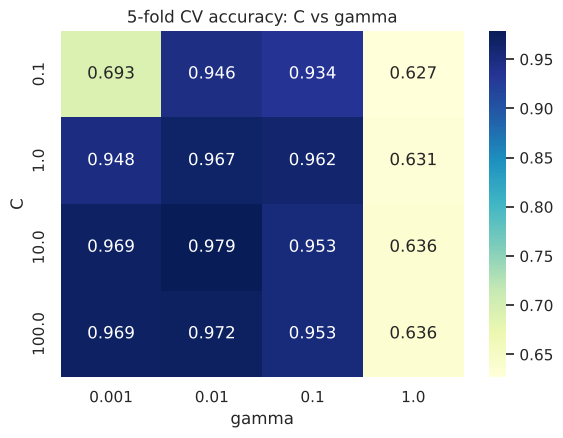

In [8]:
param_grid = {"C": [0.1, 1, 10, 100], "gamma": [0.001, 0.01, 0.1, 1]}
gs = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=5, scoring="accuracy").fit(X_train_s, y_train)
print("Best parameters:", gs.best_params_)
print("Best CV accuracy: %.4f" % gs.best_score_)
print("Test accuracy of tuned model: %.4f" % gs.score(X_test_s, y_test))

scores = pd.DataFrame(gs.cv_results_)[["param_C", "param_gamma", "mean_test_score"]]
heat = scores.pivot(index="param_C", columns="param_gamma", values="mean_test_score").astype(float)
plt.figure(figsize=(6.5, 4.5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu"); plt.title("5-fold CV accuracy: C vs gamma")
plt.ylabel("C"); plt.xlabel("gamma"); plt.show()

**How to read the heatmap:** each cell is the cross-validated accuracy for one (C, gamma) pair. The darkest cell is the best combination (here C = 10, gamma = 0.01, CV accuracy about 0.979, and the tuned model scored the same on the test set). Cells with a very small C and gamma, or a large gamma, are lighter (underfitting or overfitting).

## Result / Conclusion
- On Breast Cancer (nearly linearly separable) linear and RBF kernels perform very similarly (about 0.96 to 0.97), the default polynomial kernel is weaker, and tuned RBF reaches about 0.98. The choice of kernel matters most when the classes are **not** linearly separable, as on the moons data, where RBF (about 0.99) clearly beats linear (about 0.91).
- Scaling is essential for SVM. C and gamma control the bias-variance balance and should be tuned with cross-validation.
- Only the support vectors define the decision boundary.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is an SVM?**
A supervised algorithm that finds the hyperplane separating the classes with the **maximum margin**. It is used for classification (SVC) and regression (SVR).

**Q2. What is a hyperplane?**
A decision surface of dimension n-1 in n-dimensional space: a line in 2D, a plane in 3D.

**Q3. What are support vectors?**
The training points closest to the hyperplane (on or inside the margin). They alone determine its position; removing other points does not change it.

**Q4. What is the margin and why maximise it?**
The distance between the hyperplane and the nearest points of each class. A larger margin gives better generalisation and lower risk of overfitting.

**Q5. Hard margin vs soft margin?**
Hard margin allows no misclassification and needs perfectly separable data. Soft margin allows some violations, controlled by C, so it works with noisy, overlapping data.

**Q6. What does C control?**
The trade-off between a wide margin and training errors. Large C: fewer training errors, narrow margin, overfitting risk. Small C: wide margin, more errors allowed, underfitting risk.

**Q7. What is the kernel trick?**
Computing the dot product of data in a higher-dimensional space directly with a kernel function, without actually transforming the data. It lets SVM learn non-linear boundaries cheaply.

**Q8. Name the common kernels and when to use them.**
Linear: $K=x^Tz$, for linearly separable or high-dimensional sparse data (text). Polynomial: $K=(\gamma x^Tz+r)^d$, for curved boundaries. RBF (Gaussian): $K=\exp(-\gamma\|x-z\|^2)$, the default for general non-linear data. Sigmoid: $K=\tanh(\gamma x^Tz+r)$, rarely used.

**Q9. What is gamma in the RBF kernel?**
It controls how far a single training point's influence reaches. High gamma: small influence, complex boundary, overfitting. Low gamma: large influence, smooth boundary, underfitting.

**Q10. Why must features be scaled for SVM?**
SVM uses distances, so large-range features would dominate the margin and kernel calculation.

**Q11. How does SVM do multi-class classification?**
By combining binary classifiers: one-vs-one (scikit-learn's SVC) or one-vs-rest.

**Q12. Advantages and disadvantages of SVM?**
Advantages: effective in high dimensions, robust when a clear margin exists, memory-efficient (uses only support vectors), flexible via kernels. Disadvantages: slow on very large datasets, needs scaling and tuning, no direct probabilities (`probability=True` adds cost), and performs poorly with heavy noise or overlapping classes.

**Q13. Linear SVM vs logistic regression?**
Both are linear classifiers. SVM maximises the margin using hinge loss and depends only on support vectors; logistic regression uses log loss, gives probabilities and uses all points.

**Q14. What is hinge loss?**
$\max(0, 1 - y f(x))$: zero for points correctly classified beyond the margin, growing linearly for violations.

**Q15. How do you choose the kernel and parameters?**
Start with linear and RBF, then tune C and gamma with GridSearchCV and cross-validation.

**Q16. Why did linear and RBF give similar accuracy on Breast Cancer?**
The data is almost linearly separable, so a complex kernel adds no benefit. Non-linear kernels help only when the classes are not linearly separable.

**Q16b. Which kernel did best and worst in your run, and why?**
RBF was best (0.972) with linear close behind (0.958); polynomial was worst (0.895, recall 0.72). The default degree-3 polynomial kernel is sensitive to scaling and its settings (`degree`, `coef0`), so it needs tuning. The linear-vs-RBF gap is only 2 patients on 143 test samples, so it is not significant.

**Q17. What is the difference between `SVC` and `LinearSVC`?**
`SVC(kernel='linear')` uses libsvm (supports kernels, slower on big data). `LinearSVC` uses liblinear (linear only, much faster on large datasets).

**Q18. How do you get class probabilities from an SVM?**
Set `probability=True`; scikit-learn fits Platt scaling using internal cross-validation (slower).

**Q19. What does the "dual form" of SVM mean?**
The optimisation is written in terms of Lagrange multipliers, where only support vectors have non-zero multipliers, and the data appears only through dot products, which is what makes the kernel trick possible.

**Q20. Is SVM sensitive to outliers?**
A hard-margin SVM is; a soft-margin SVM with smaller C is more robust.

**Q21. What is `gamma='scale'`?**
The default $\gamma = 1/(n_{features}\cdot Var(X))$, which adapts to the data scale.

## B. Questions about the graphs

**G1. What does the decision boundary plot show?**
Coloured regions show the class predicted at each point in the plane; the boundary between colours is the decision boundary. Points are the data coloured by true class; points in the wrong region are misclassified.

**G2. How does the linear boundary differ from the RBF boundary?**
Linear gives straight lines (hyperplanes); RBF gives smooth, curved, flexible regions that wrap around clusters.

**G3. What are the circled points?**
Support vectors.

**G4. Why does the linear kernel fail on the moons data?**
The classes are interleaved and not linearly separable, so no straight line can separate them. RBF bends the boundary around the moons.

**G5. What would a very high gamma look like?**
Tiny islands around individual points (very wiggly boundary): overfitting. A very low gamma gives an almost straight boundary: underfitting.

**G6. What if C is very large?**
The model tries to classify every training point correctly: narrow margin and possible overfitting. Small C gives a wider margin that allows some errors (more generalisation).

**G7. How do you read the 3x3 C/gamma grid?**
Moving down increases C, moving right increases gamma. Top-left is smooth and underfit; bottom-right is wiggly and overfit; the middle is the best balance.

**G8. How do you read the GridSearch heatmap?**
Each cell is the cross-validated accuracy for a (C, gamma) pair; the highest value gives the best hyperparameters.

**G9. What does the support-vector count bar chart show?**
How many training points define the boundary for each kernel. Fewer means a simpler boundary.

**G10. What do the confusion matrices show?**
Correct (diagonal) and wrong (off-diagonal) predictions for each kernel; FN means a missed malignant case.

## C. Code questions

**C1. Why scale before SVM, and why fit the scaler on training data only?**
SVM is distance-based; fitting on train only avoids data leakage.

**C2. What does `n_support_` return?**
The number of support vectors for each class.

**C3. What does `GridSearchCV` do?**
Tries every combination in the parameter grid with cross-validation and keeps the best.

**C4. What does `np.meshgrid` do in the boundary plot?**
Creates a grid of points covering the plane; the model predicts a class for each, and `contourf` colours the regions.